### 1. Dataset

The dataset used for this capstone project is a Superstore sales dataset containing information about customer orders, shipping methods, customers, locations, product categories, and sales.

The dataset contains 9,800 rows and 18 columns. It includes both categorical and numerical variables, making it suitable for exploratory data analysis and visualization.

The main business objective is to analyze sales patterns and identify useful insights that can help improve business performance.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv(r"C:\Users\YESS\Downloads\train.csv" )

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


### Check the Dataset Size

In [38]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9800
Number of columns: 18


### Check Missing Values

In [39]:
df.isnull().sum()


# This shows that our dataset has 11 missing postal codes values.

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

### Check Duplicate 

In [40]:
df.duplicated().sum()

np.int64(0)

This confirmed that there are no duplicte rows.

### Dataset Summary


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

This gives us information about:

Number of rows,
Number of columns,
Column names,
Data types,
Non-null values and
Memory usage

### Data Cleaning 
Data cleaning is the process of identifying and correcting problems in a dataset before analysis.

The cleaning process for this project includes checking for missing values, duplicate records, and incorrect data types.

In [42]:
# Create a copy of the original dataset
df_clean = df.copy()

# Display the first five rows
df_clean.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


### Handling The Missing Values

In [43]:
# Fill missing postal codes with 0
df_clean["Postal Code"] = df_clean["Postal Code"].fillna(0)

In [44]:
df_clean.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

Why did we do this?

We don't want to simply delete 11 complete sales records just because their postal code is missing. Filling the missing postal code allows us to preserve those sales records

### Checking for Duplicated rows

In [45]:
# Count duplicate rows
df_clean.duplicated().sum()

np.int64(0)

the above result confirms that there are no duplicate.

### Fix The Data Column

In [46]:
# Convert date columns from DD/MM/YYYY format to datetime
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    dayfirst=True
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    dayfirst=True
)

In [47]:
df_clean[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

### Check All Data Types

In [48]:
df_clean.dtypes

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code             float64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
dtype: object

### Check Numerical Columns

In [49]:
df_clean.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales
count,9800.000000,9800,9800,9800.000000,9800.000000
mean,4900.500000,2017-05-01 05:13:51.673469440,2017-05-05 04:17:52.653061120,55211.280918,230.769059
min,1.000000,2015-01-03 00:00:00,2015-01-07 00:00:00,0.000000,0.444000
25%,2450.750000,2016-05-24 00:00:00,2016-05-27 18:00:00,23223.000000,17.248000
50%,4900.500000,2017-06-26 00:00:00,2017-06-29 00:00:00,57551.000000,54.490000
75%,7350.250000,2018-05-15 00:00:00,2018-05-19 00:00:00,90008.000000,210.605000
max,9800.000000,2018-12-30 00:00:00,2019-01-05 00:00:00,99301.000000,22638.480000
std,2829.160653,NaN,NaN,32076.677954,626.651875


### Ckeck For Final Missing Value

In [50]:
df_clean.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

Here is to confirm that all missing values has been handled

### Data Cleaning Summary
The dataset was inspected for missing values, duplicate records, and incorrect data types.

There were 11 missing values in the Postal Code column. These missing values were replaced with 0 so that the corresponding sales records could be retained for analysis.

The dataset contained no duplicate rows.

The Order Date and Ship Date columns were initially stored as object data types. They were converted to datetime format to allow accurate date-based analysis.

After cleaning, the dataset retained 9,800 rows and 18 columns and was ready for exploratory data analysis.

### EXPLORATORY DATA ANALYSIS
Exploratory Data Analysis (EDA) is used to understand the main patterns, relationships, and characteristics of the dataset.

In this section, sales and business performance will be examined using GroupBy analysis, summary statistics, correlation analysis, and outlier detection.

### GroupBy Analysis #1: Sales by Category

In [51]:
sales_by_category = df_clean.groupby("Category")["Sales"].sum().sort_values(ascending=False)

sales_by_category

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

This calculates the total sales for each product category

### GroupBy Analysis 1: Sales by Category

The analysis groups the orders by product category and calculates the total sales generated by each category.

This helps identify which product categories contribute the most revenue to the business. The category with the highest total sales represents the strongest contributor to overall revenue, while the category with the lowest sales may require further investigation.

### GroupBy Analysis #2: Sales by Region

In [52]:
region_performance = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum")
).sort_values("Total_Sales", ascending=False)

region_performance.round(2)

,Total_Sales
Region,
West,710219.68
East,669518.73
Central,492646.91
South,389151.46


### GroupBy Analysis 2: Regional Sales Performance

The dataset was grouped by region to compare total sales across different geographical areas.

This analysis helps identify the strongest and weakest-performing regions. Understanding regional performance can help management determine where sales are strongest and where additional marketing or business attention may be required.


### GroupBy Analysis #3: Sales by Customer Segment

In [53]:
# Which customer segment generates most sales
sales_by_segment = df_clean.groupby("Segment")["Sales"].sum().sort_values(
    ascending=False
)

sales_by_segment.round(2)

Segment
Consumer       1148060.53
Corporate       688494.07
Home Office     424982.18
Name: Sales, dtype: float64

### GroupBy Analysis 3: Sales by Customer Segment

The data was grouped by customer segment to determine which type of customer contributes the most sales.

This analysis provides insight into the customer groups that generate the greatest revenue. The results can help the business prioritize marketing strategies and customer retention efforts.


### Which state generates the highest sales?

In [54]:
sales_by_state = df_clean.groupby("State")["Sales"].sum().sort_values(
    ascending=False
)

sales_by_state.head(10).round(2)


State
California      446306.46
New York        306361.15
Texas           168572.53
Washington      135206.85
Pennsylvania    116276.65
Florida          88436.53
Illinois         79236.52
Michigan         76136.07
Ohio             75130.35
Virginia         70636.72
Name: Sales, dtype: float64

# Correlation Analysis



### Correlation matrix

Correlation helps us examine whether numerical variables tend to move together

In [55]:
# Identify the numerical columns
df_clean.select_dtypes(include="number").columns

Index(['Row ID', 'Postal Code', 'Sales'], dtype='object')

In [56]:
# Correlation matrix
correlation_matrix = df_clean.select_dtypes(include="number").corr()

correlation_matrix.round(2)

,Row ID,Postal Code,Sales
Row ID,1.00,0.01,0.00
Postal Code,0.01,1.00,-0.03
Sales,0.00,-0.03,1.00


### Correlation Visualization

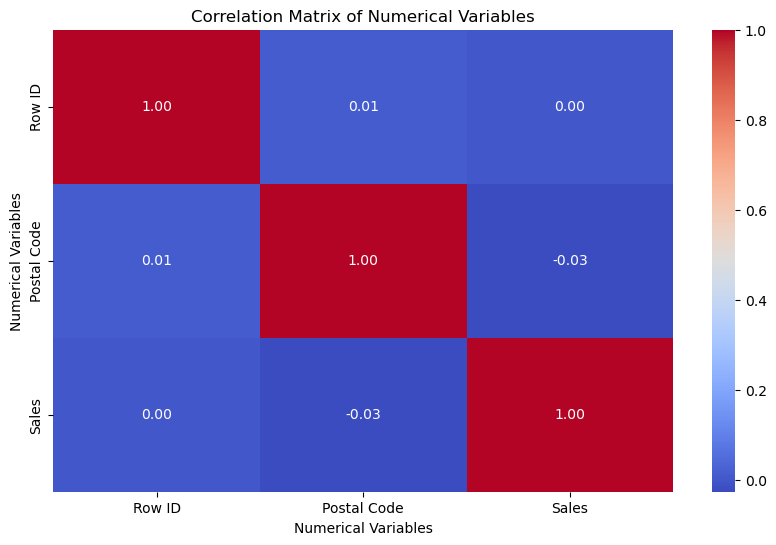

In [57]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.xlabel("Numerical Variables")
plt.ylabel("Numerical Variables")

plt.show()

### Correlation Analysis


The correlation matrix was used to examine relationships between the numerical variables in the dataset.

The heatmap makes it easier to identify variables that have strong positive or negative relationships. These relationships can help identify patterns that deserve further investigation.

However, correlation does not necessarily mean that one variable causes another. Therefore, the results are interpreted as relationships rather than direct cause-and-effect relationships.


## Outlier Detection

In [58]:
Q1 = df_clean["Sales"].quantile(0.25)
Q3 = df_clean["Sales"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 17.248
Q3: 210.60500000000002
IQR: 193.35700000000003


## Outlier Boundaries

In [59]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -272.7875000000001
Upper Bound: 500.6405000000001


## Identify the Outlier

In [60]:
sales_outliers = df_clean[
    (df_clean["Sales"] < lower_bound) |
    (df_clean["Sales"] > upper_bound)
]

sales_outliers.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
7,8,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520
10,11,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840
11,12,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002033,Technology,Phones,Konftel 250 Conference phone - Charcoal black,911.4240


In [61]:
print("Number of Sales Outliers:", len(sales_outliers))

Number of Sales Outliers: 1145


In [62]:
outlier_percentage = (len(sales_outliers) / len(df_clean)) * 100

print("Percentage of Sales Outliers:", round(outlier_percentage, 2), "%")

Percentage of Sales Outliers: 11.68 %


## Outlier Visualization

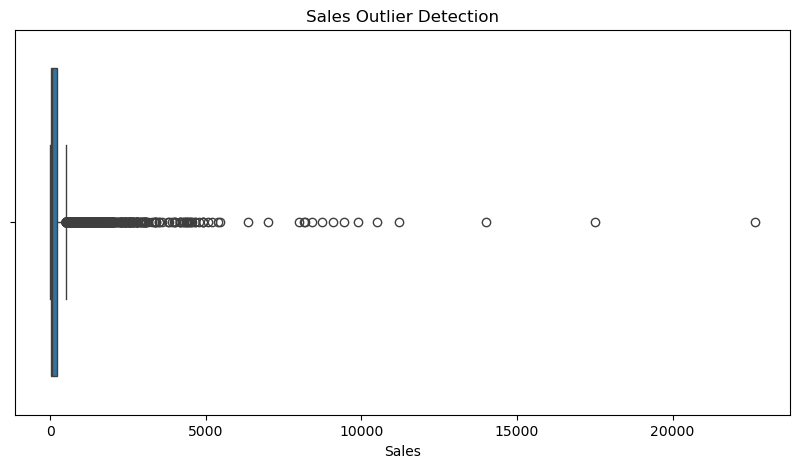

In [63]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["Sales"])

plt.title("Sales Outlier Detection")
plt.xlabel("Sales")

plt.show()

## Outlier Analysis



The Sales column was analyzed using the Interquartile Range (IQR) method to identify unusually high or low sales values.

The box plot shows the distribution of sales and highlights observations that fall outside the expected range.

These outliers should not automatically be removed because unusually large sales may represent legitimate high-value orders. Instead, they should be investigated to determine whether they represent genuine business activity or data-quality problems.


## # 4. Data Visualization

Data visualization helps communicate important patterns and relationships discovered during exploratory data analysis.

In this section, charts are used to compare sales across product categories, regions, and customer segments and to examine the distribution of sales. A subplot grid is also used to compare multiple business dimensions in a single figure.


## Total Sales by Category

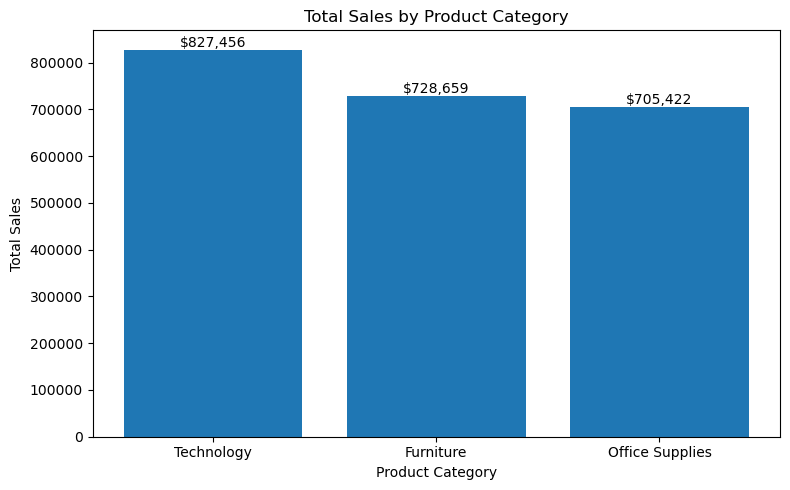

In [64]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    sales_by_category.index,
    sales_by_category.values
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Finding: Sales by Product Category

Technology generated the highest total sales at **$827,455.87**, followed by Furniture at **$728,658.58** and Office Supplies at **$705,422.33**.

Technology contributed approximately **36.6% of total sales**, making it the strongest-selling category in this dataset. Management should investigate which Technology products contribute most to this result and whether similar opportunities exist in other categories.

## Total Sales by region

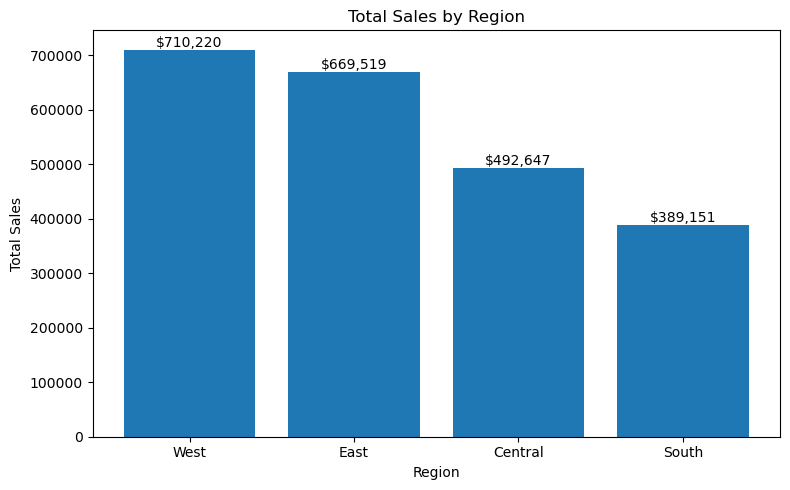

In [65]:
region_sales = df_clean.groupby("Region")["Sales"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    region_sales.index,
    region_sales.values
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Finding: Regional Sales Performance

The **West region generated the highest sales at $710,219.68**, followed by the East at **$669,518.73**. Central generated **$492,646.91**, while the South recorded the lowest sales at **$389,151.46**.

The West contributed approximately **31.4% of total sales**, compared with approximately **17.2%** from the South. Management should investigate possible reasons for these differences—such as market size, customer demand, product availability, or marketing activity—before deciding on specific interventions.

## Sales Distribution

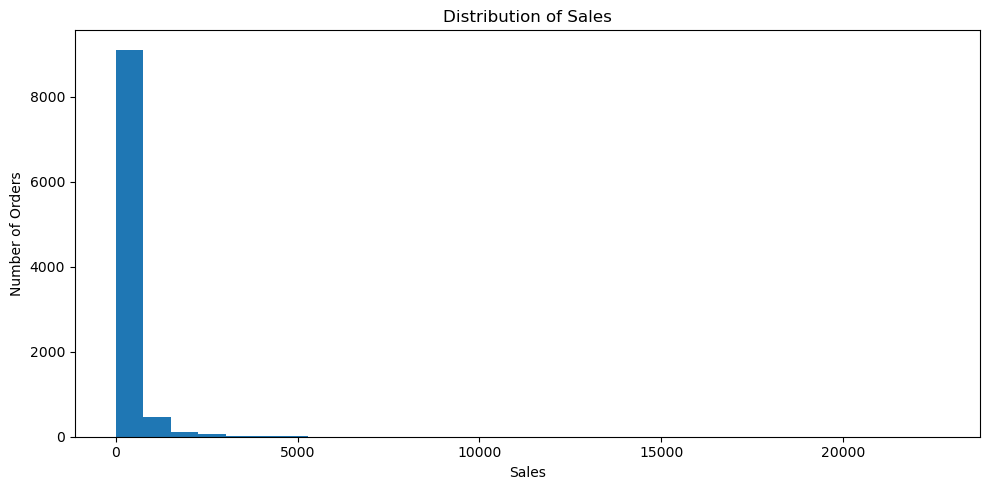

In [66]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Sales"],
    bins=30
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

### Finding: Sales Distribution

The average sales value was **$230.77**, while the median was **$54.49**. Because the average is substantially higher than the median, the distribution is likely right-skewed, with some high-value orders pulling the average upward.

These orders should be investigated to understand which products, customer segments, or regions are associated with them. They should not automatically be removed because they may be legitimate transactions.

## SUBPLOT GRID

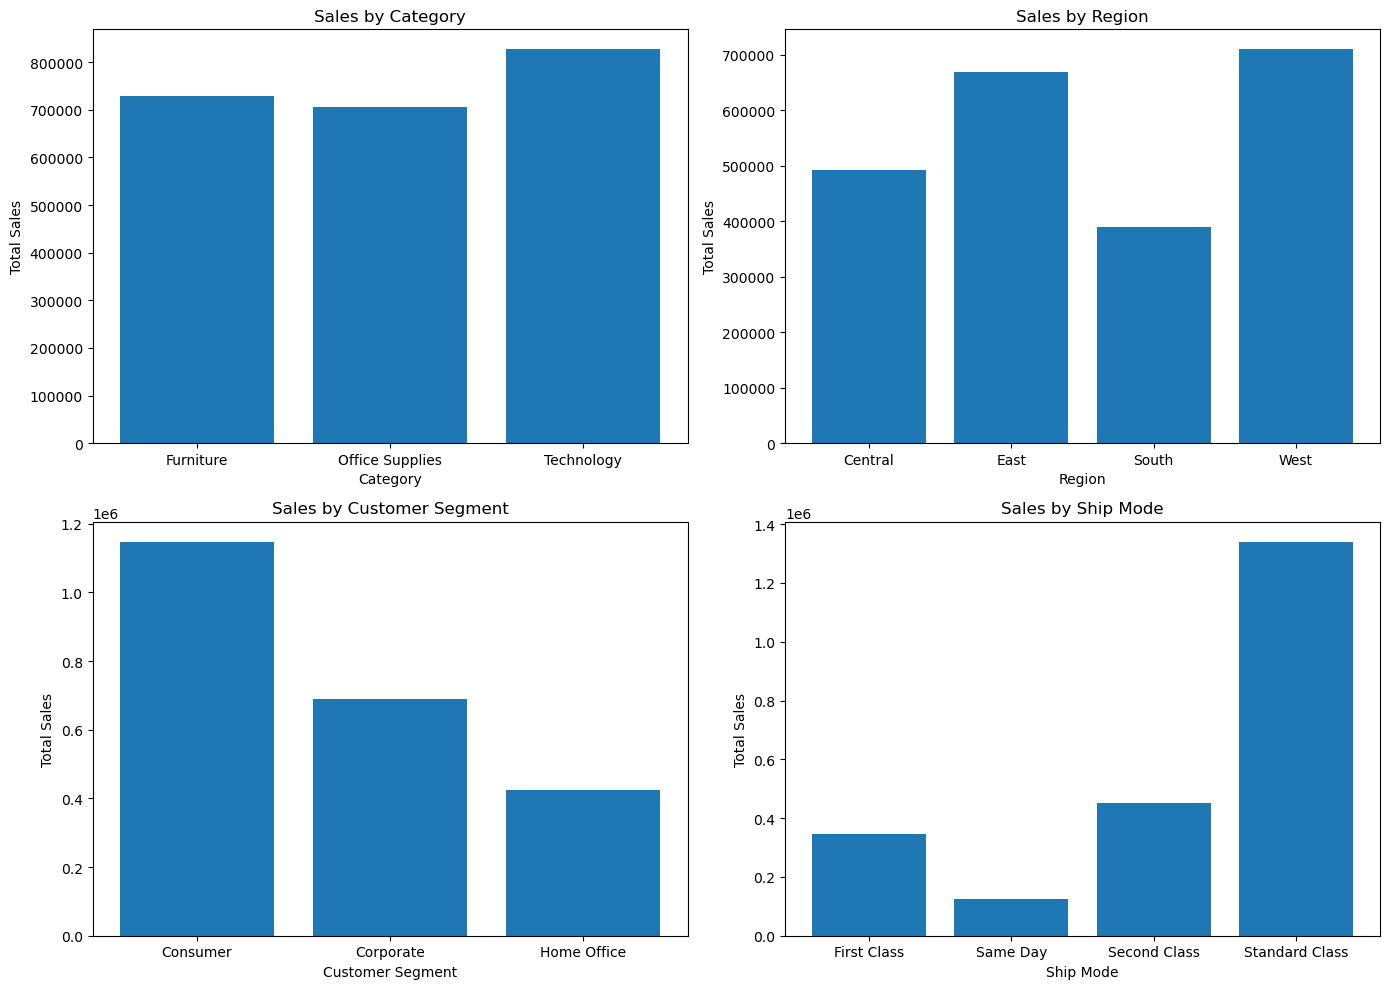

In [67]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# -------------------------
# Chart 1: Sales by Category
# -------------------------
category_sales = df_clean.groupby("Category")["Sales"].sum()

axes[0, 0].bar(
    category_sales.index,
    category_sales.values
)

axes[0, 0].set_title("Sales by Category")
axes[0, 0].set_xlabel("Category")
axes[0, 0].set_ylabel("Total Sales")


# -------------------------
# Chart 2: Sales by Region
# -------------------------
region_sales = df_clean.groupby("Region")["Sales"].sum()

axes[0, 1].bar(
    region_sales.index,
    region_sales.values
)

axes[0, 1].set_title("Sales by Region")
axes[0, 1].set_xlabel("Region")
axes[0, 1].set_ylabel("Total Sales")


# -------------------------
# Chart 3: Sales by Segment
# -------------------------
segment_sales = df_clean.groupby("Segment")["Sales"].sum()

axes[1, 0].bar(
    segment_sales.index,
    segment_sales.values
)

axes[1, 0].set_title("Sales by Customer Segment")
axes[1, 0].set_xlabel("Customer Segment")
axes[1, 0].set_ylabel("Total Sales")


# -------------------------
# Chart 4: Sales by Ship Mode
# -------------------------
ship_sales = df_clean.groupby("Ship Mode")["Sales"].sum()

axes[1, 1].bar(
    ship_sales.index,
    ship_sales.values
)

axes[1, 1].set_title("Sales by Ship Mode")
axes[1, 1].set_xlabel("Ship Mode")
axes[1, 1].set_ylabel("Total Sales")

plt.tight_layout()
plt.show()

### Key Findings from the Subplot Grid

- **Product category:** Technology led with sales of **$827,455.87**.
- **Region:** West led with sales of **$710,219.68**.
- **Customer segment:** Consumer led with sales of **$1,148,060.53**.
- **Shipping method:** Use the displayed subplot to identify the highest-selling shipping method; report its value after running the chart rather than guessing.

## Visualization Summary

Several visualizations were created to communicate the major patterns identified during exploratory data analysis.

The charts compare sales across product categories, geographical regions, customer segments, and shipping methods. A histogram was also used to examine the distribution of individual sales values.

A 2 × 2 subplot grid was created to compare four different business dimensions in a single figure. All visualizations include appropriate titles and labelled axes.


In [68]:
print("Sales by Category:")
print(sales_by_category.round(2))

print("\nSales by Region:")
print(region_performance.round(2))

print("\nSales by Customer Segment:")
print(sales_by_segment.round(2))

Sales by Category:
Category
Technology         827455.87
Furniture          728658.58
Office Supplies    705422.33
Name: Sales, dtype: float64

Sales by Region:
         Total_Sales
Region              
West       710219.68
East       669518.73
Central    492646.91
South      389151.46

Sales by Customer Segment:
Segment
Consumer       1148060.53
Corporate       688494.07
Home Office     424982.18
Name: Sales, dtype: float64


In [69]:
print("Total Sales:", df_clean["Sales"].sum())
print("Average Order Sales:", df_clean["Sales"].mean())
print("Median Order Sales:", df_clean["Sales"].median())

Total Sales: 2261536.7827
Average Order Sales: 230.76905945918367
Median Order Sales: 54.489999999999995


In [70]:
consumer_sales = sales_by_segment["Consumer"]
total_sales = df_clean["Sales"].sum()

consumer_percentage = (consumer_sales / total_sales) * 100

print("Consumer Sales:", round(consumer_sales, 2))
print("Total Sales:", round(total_sales, 2))
print("Consumer Share of Total Sales:", round(consumer_percentage, 2), "%")

Consumer Sales: 1148060.53
Total Sales: 2261536.78
Consumer Share of Total Sales: 50.76 %


# 5. Business Story

## Context

The Superstore dataset contains 9,800 sales records covering customers, products, regions, customer segments, shipping methods, and sales.

The dataset generated total sales of approximately **$2.26 million**. The purpose of this analysis is to understand where sales are coming from and identify patterns that could help the business improve its sales performance.

The analysis focuses on product categories, geographical regions, customer segments, and order values.

## Finding

The analysis shows that **Technology is the highest-selling product category**, generating approximately **$827,455.87** in sales. Furniture generated approximately **$728,658.58**, while Office Supplies generated approximately **$705,422.33**.

This indicates that Technology contributes the largest amount of sales among the three product categories.

Regional performance also varies considerably. The **West region generated the highest sales at approximately $710,219.68**, followed by the East with $669,518.73. The South generated the lowest regional sales at approximately $389,151.46.

## Deeper Finding

The customer segment analysis provides another important insight.

The **Consumer segment generated approximately $1,148,060.53**, making it the largest contributor to total sales. Corporate customers generated $688,494.07, while Home Office customers generated $424,982.18.

This means that Consumer customers account for approximately half of the total sales in the dataset.

The order-value analysis also reveals an important pattern. The average order value is approximately **$230.77**, while the median order value is only **$54.49**. The difference between the average and median suggests that some relatively large orders are increasing the average sales value.

These high-value orders should be investigated further to determine which products, customers, regions, or other characteristics are associated with them.

## Recommendation

The business should continue monitoring the strong sales performance of the **Technology category**, the **West region**, and the **Consumer segment**.

Management could investigate which products and customer characteristics are responsible for the strong Technology and Consumer sales performance and determine whether similar opportunities exist in lower-performing areas.

The business should also investigate the differences between regions, particularly the lower sales recorded in the South, to understand whether factors such as customer demand, product availability, marketing activity, or market size may contribute to the difference.

Finally, the business should examine the unusually large orders identified during outlier analysis. Understanding these high-value purchases could help identify opportunities to increase order value or develop strategies for similar customers.

## Business Impact

The findings provide a clearer understanding of where the company's sales are being generated.

Focusing analysis and resources on strong-performing products and customer groups can help management understand existing sources of sales, while investigating lower-performing regions can reveal potential areas for improvement.

The analysis therefore provides data-driven information that can support decisions about **product planning, customer targeting, marketing activities, and regional sales strategies**.


# 6. Cause, Effect, and Business Impact

## Cause

The analysis shows that sales are concentrated among particular customer segments, product categories, and regions.

The Consumer segment generated approximately **$1.15 million** in sales, while Technology generated approximately **$827,456**. The West region generated the highest regional sales at approximately **$710,220**.

The dataset alone does not prove why these areas generate higher sales. Possible factors that could be investigated include customer demand, product popularity, market size, marketing activity, and product availability.

## Effect

Because sales are concentrated in certain segments, categories, and regions, changes in these areas could have a noticeable effect on overall sales performance.

The Consumer segment represents approximately **50.8% of total sales**, making it an important customer group for the business.

The difference between the average order value of **$230.77** and the median of **$54.49** also indicates that a relatively small number of high-value orders may be influencing the overall average.

## Business Impact

Understanding these patterns can help management make more informed decisions about customer targeting, product planning, marketing, and regional strategies.

The business can use the findings to investigate successful products and customer groups, understand differences between regions, and examine high-value orders for potential opportunities.

However, further analysis would be required to determine the specific causes behind these differences before making major business decisions.


# 8. SQL Analysis

SQL (Structured Query Language) was used with PostgreSQL and pgAdmin to analyze the Superstore sales dataset. The queries calculate total sales and compare sales performance across product categories, geographical regions, and customer segments.

The SQL results are compared with the Python analysis to verify the main findings and demonstrate the use of SQL for business data analysis.

### Query 1- Total sales

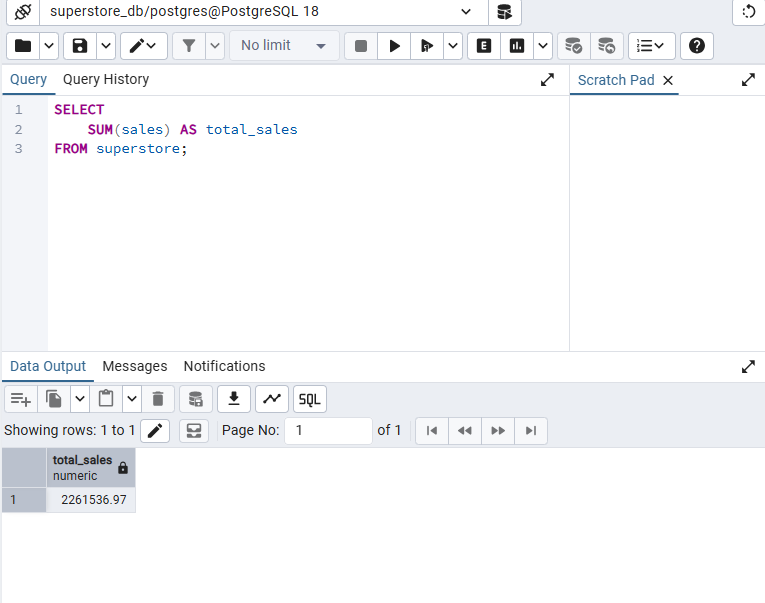


### Query 2- Sales by product category
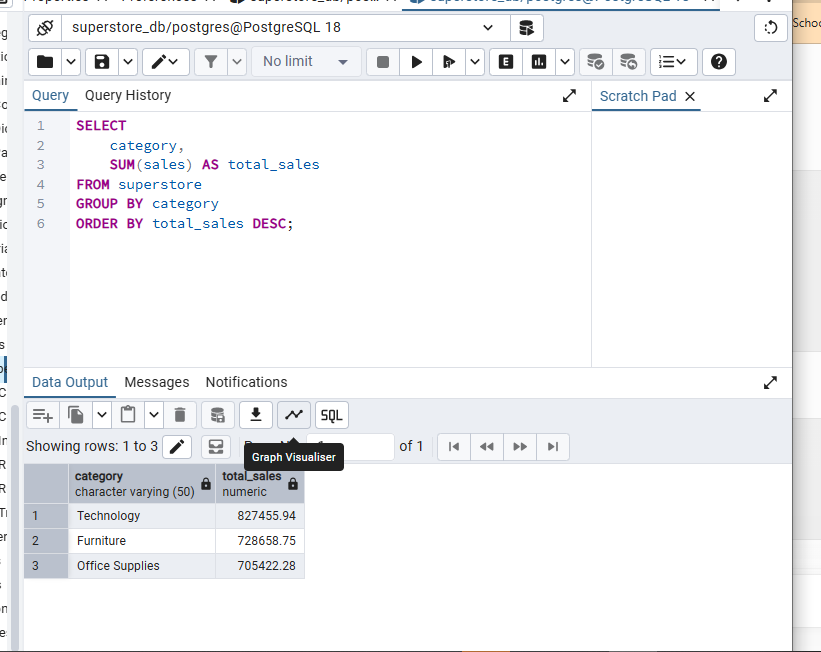

### Sales by region

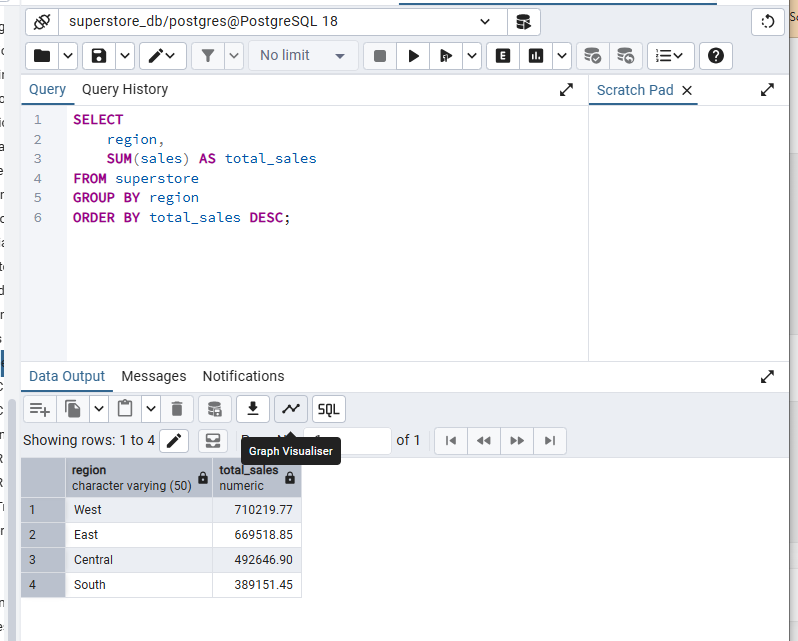


# Finding: The West region has the highest sales, while the South has the lowest.

## Sales by customer segment


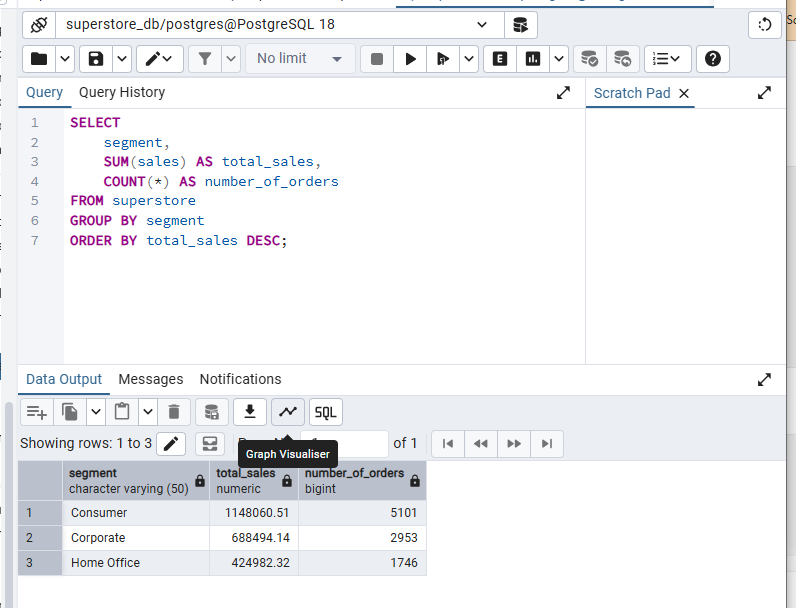


# Finding: The consumer segment generated the highest total sales. 

## SQL Analysis

SQL was used in PostgreSQL through pgAdmin to analyse the Superstore dataset containing 9,800 sales records.

Four queries were performed:

1. **Total Sales:** Calculated the overall sales value.
2. **Category Analysis:** Compared sales across Technology, Furniture, and Office Supplies.
3. **Regional Analysis:** Compared sales performance across the West, East, Central, and South regions.
4. **Customer Segment Analysis:** Compared sales generated by Consumer, Corporate, and Home Office customers.

### Key Findings

- Technology recorded the highest sales among the three product categories.
- The West region generated the highest regional sales.
- The South region generated the lowest regional sales.
- The Consumer segment contributed the largest share of total sales.

### Business Recommendation

Management should investigate the products and customer purchasing patterns contributing to Technology's strong performance. The business should also examine why sales differ across regions and explore opportunities to improve performance in the South. These results identify areas for further investigation; they do not, by themselves, establish the causes of the differences.

https://github.com/azevos-cloud/Cybersecurity-portfolio